## Mecanismo de transmisión de la política monetaria y su impacto en las finanzas públicas de México
### Análisis exploratorio del dataset integrado

**Fuentes:** 
* Tasa de Interés Interbancaria de Equilibrio del Banco de México (TIIE)
* Deuda Pública de la Secretaría de Hacienda y Crédito Público (SHCP)
* Ingresos, Gastos y Financiamiento del Sector Público de la Secretaría de Hacienda y Crédito Público (SHCP)
* Indicador Global de la Actividad Económica del Instituto Nacional de Estadística y Geografía (IGAE - INEGI)
* Índice Nacional de Precios al Consumidor del Instituto Nacional de Estadística y Geografía (INPC - INEGI)

**Objetivo:**
Explorar y graficar series de tiempo macroeconómicas (2011-2026) para evaluar cuantitativamente el mecanismo de transmisión de la política monetaria en México, determinando los rezagos temporales y los efectos de los cambios en las tasas de interés sobre la inflación (INPC), el crecimiento económico (IGAE) y las finanzas públicas (ingresos y gastos de la SHCP).


### 0. Configuración

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import pandas as pd
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

plt.style.use("ggplot")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", None)

# Ajusta la ruta según la ubicación del notebook (aquí se asume notebooks/ en la raíz del repo)
PARQUET_PATH = Path("../data/processed/NOMBRE_DEL_ARCHIVO.parquet")  # TODO: cambiar nombre

### 1. Introducción

In [2]:
### PONER CÓDIGO

### 2.

In [3]:
### PONER CÓDIGO

### 3.

In [4]:
### PONER CÓDIGO

### 4. Pregunta Analítica 2
> **¿Ha sido la tasa de interés real positiva en México entre 2012 y 2026, y reacciona la TIIE a la inflación medida con el INPC?**

Se divide en dos partes que responden las consultas de la sección siguiente:

1. **Nivel:** comparando la TIIE con la inflación anual, ¿qué tan seguido y por cuánto la tasa real (TIIE menos inflación) fue negativa?
2. **Reacción:** ¿se mueve la TIIE junto con la inflación o después de ella? ¿con cuántos meses de rezago?

**Por qué importa:** una tasa real negativa significa que el dinero prestado se abarata en términos de poder adquisitivo, lo que afecta ahorradores, deudores y el costo real del financiamiento público.

In [5]:
spark = (
    SparkSession.builder
    .appName("Actividad12_TIIE_INPC")
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate()
)

# Rutas candidatas, de la más a la menos preferida. Ajusta la primera si el
# Parquet integrado del pipeline tiene otro nombre en tu repositorio.
CANDIDATAS = [
    "data/processed/macro_finanzas_consolidado.parquet",
    "data/raw/macro_finanzas_consolidado.csv",
    "macro_finanzas_consolidado.csv",
]
CANDIDATAS = CANDIDATAS + ["../" + c for c in CANDIDATAS]  # por si el notebook está en notebooks/

ruta = next((c for c in CANDIDATAS if Path(c).exists()), None)
if ruta is None:
    raise FileNotFoundError(f"No se encontró el dataset en ninguna de estas rutas: {CANDIDATAS}")

if ruta.endswith(".parquet"):
    crudo = spark.read.parquet(ruta)
else:
    crudo = spark.read.csv(ruta, header=True, inferSchema=True)

# Sólo se necesitan tres columnas para esta pregunta.
macro = crudo.select(
    F.col("CICLO").cast("string").alias("CICLO"),
    F.col("TIIE").cast("double").alias("TIIE"),
    F.col("VALOR_INPC").cast("double").alias("VALOR_INPC"),
)
macro.createOrReplaceTempView("macro")

print(f"[FUENTE] {ruta}")
macro.printSchema()
macro.show(5)

[FUENTE] ../data/processed/macro_finanzas_consolidado.parquet
root
 |-- CICLO: string (nullable = true)
 |-- TIIE: double (nullable = true)
 |-- VALOR_INPC: double (nullable = true)

+-------+------------------+---------------+
|  CICLO|              TIIE|     VALOR_INPC|
+-------+------------------+---------------+
|2011-01|4.5495238095238095|75.295991345634|
|2011-02| 4.518421052631578|75.578460244005|
|2011-03| 4.488636363636363|75.723450928541|
|2011-04| 4.504736842105263| 75.71744095198|
|2011-05| 4.466363636363637|75.159264378869|
+-------+------------------+---------------+
only showing top 5 rows



## 4.1. Descripción del dataset final

| Elemento | Descripción |
|---|---|
| **Origen** | `macro_finanzas_consolidado`: dataset integrado por el pipeline PySpark a partir de las fuentes del proyecto (deuda, finanzas públicas, IGAE, TIIE e INPC). |
| **Columnas usadas** | `CICLO` (mes, texto `AAAA-MM`), `TIIE` (tasa de interés interbancaria de equilibrio, en % anual) y `VALOR_INPC` (nivel del índice nacional de precios al consumidor). |
| **Periodo cubierto** | Se calcula en la celda siguiente (de enero de 2011 a junio de 2026 en la versión actual). |
| **Granularidad** | Una fila por mes, sin cortes por actividad ni por región. |

Antes de consultar se comprueban las condiciones que la pregunta necesita: sin nulos en las dos columnas, sin meses repetidos y sin huecos en la serie. Esto último importa porque el cálculo de inflación anual compara cada mes con el de 12 filas atrás.

In [6]:
resumen = spark.sql("""
    SELECT COUNT(*)                AS FILAS,
           COUNT(DISTINCT CICLO)   AS MESES_DISTINTOS,
           MIN(CICLO)              AS PRIMER_MES,
           MAX(CICLO)              AS ULTIMO_MES,
           SUM(CASE WHEN TIIE IS NULL THEN 1 ELSE 0 END)       AS NULOS_TIIE,
           SUM(CASE WHEN VALOR_INPC IS NULL THEN 1 ELSE 0 END) AS NULOS_INPC
    FROM macro
""").first()

meses_esperados = (
    (int(resumen.ULTIMO_MES[:4]) - int(resumen.PRIMER_MES[:4])) * 12
    + int(resumen.ULTIMO_MES[5:7]) - int(resumen.PRIMER_MES[5:7]) + 1
)

assert resumen.NULOS_TIIE == 0 and resumen.NULOS_INPC == 0, "Hay nulos en TIIE o VALOR_INPC"
assert resumen.FILAS == resumen.MESES_DISTINTOS, "Hay meses duplicados"
assert resumen.FILAS == meses_esperados, f"Hay huecos: {resumen.FILAS} filas vs {meses_esperados} meses esperados"

print(f"Periodo: {resumen.PRIMER_MES} a {resumen.ULTIMO_MES} | {resumen.FILAS} meses | validaciones OK")

Periodo: 2011-01 a 2026-06 | 186 meses | validaciones OK


## 4.2. Consultas de consumo (Spark SQL)

### Qué se calcula una vez en el pipeline y qué se calcula al consultar

| Resultado | Dónde se obtiene | Comentario |
|---|---|---|
| Unión de fuentes, limpieza, `CICLO` mensual, `TIIE`, `VALOR_INPC` | **Pipeline (ya preparado)** | Se consume tal cual; no se reprocesa. |
| Inflación anual a partir del INPC | **Consulta 1 (al consultar)** | Depende de la definición elegida para esta pregunta (variación contra el mismo mes del año anterior). |
| Tasa real y marca de tasa real negativa | **Consulta 1 (al consultar)** | Derivada de la inflación anual. |
| Resumen anual | **Consulta 2 (al consultar)** | Agregación ligera sobre la vista de la consulta 1. |
| Correlaciones con rezago | **Consulta 3 (al consultar)** | Se recalcula con cada rezago que se pruebe. |

Si el equipo decide que la inflación anual se usará en otras preguntas, puede moverse al ETL (`enrich.py`) en una iteración posterior; por ahora se mantiene en la capa de consumo para no tocar el pipeline.

### Consulta 1 — Inflación anual y tasa real

In [7]:
tasa_real = spark.sql("""
    WITH base AS (
        SELECT CICLO,
               TIIE,
               VALOR_INPC,
               ROUND((VALOR_INPC / LAG(VALOR_INPC, 12) OVER (ORDER BY CICLO) - 1) * 100, 4) AS INFLACION_ANUAL
        FROM macro
    )
    SELECT CICLO,
           TIIE,
           VALOR_INPC,
           INFLACION_ANUAL,
           ROUND(TIIE - INFLACION_ANUAL, 4)                         AS TASA_REAL,
           CASE WHEN TIIE - INFLACION_ANUAL < 0 THEN 1 ELSE 0 END   AS TASA_REAL_NEGATIVA
    FROM base
    WHERE INFLACION_ANUAL IS NOT NULL      -- los primeros 12 meses no tienen mes comparable
    ORDER BY CICLO
""")
tasa_real.createOrReplaceTempView("tasa_real")
tasa_real.cache()

print(f"Filas con inflación anual calculable: {tasa_real.count()}")
tasa_real.show(5)
tasa_real.orderBy(F.col("CICLO").desc()).show(3)

Filas con inflación anual calculable: 174
+-------+------------------+---------------+---------------+---------+------------------+
|  CICLO|              TIIE|     VALOR_INPC|INFLACION_ANUAL|TASA_REAL|TASA_REAL_NEGATIVA|
+-------+------------------+---------------+---------------+---------+------------------+
|2012-01|4.4790909090909095|78.343049462107|         4.0468|   0.4323|                 0|
|2012-02|             4.497|78.502313840976|         3.8686|   0.6284|                 0|
|2012-03| 4.497619047619048|78.547388665184|         3.7293|   0.7683|                 0|
|2012-04| 4.483157894736842|78.300979626179|         3.4121|   1.0711|                 0|
|2012-05| 4.505454545454546|78.053819340105|         3.8512|   0.6543|                 0|
+-------+------------------+---------------+---------------+---------+------------------+
only showing top 5 rows

+-------+-----------------+----------+---------------+---------+------------------+
|  CICLO|             TIIE|VALOR_INPC|I

### Consulta 2 — Resumen por año

In [8]:
por_anio = spark.sql("""
    SELECT SUBSTR(CICLO, 1, 4)              AS ANIO,
           COUNT(*)                         AS MESES,
           ROUND(AVG(TIIE), 2)              AS TIIE_PROM,
           ROUND(AVG(INFLACION_ANUAL), 2)   AS INFLACION_PROM,
           ROUND(AVG(TASA_REAL), 2)         AS TASA_REAL_PROM,
           SUM(TASA_REAL_NEGATIVA)          AS MESES_TASA_REAL_NEG
    FROM tasa_real
    GROUP BY SUBSTR(CICLO, 1, 4)
    ORDER BY ANIO
""")
por_anio.show(20)

+----+-----+---------+--------------+--------------+-------------------+
|ANIO|MESES|TIIE_PROM|INFLACION_PROM|TASA_REAL_PROM|MESES_TASA_REAL_NEG|
+----+-----+---------+--------------+--------------+-------------------+
|2012|   12|      4.5|          4.11|          0.38|                  3|
|2013|   12|     3.99|          3.81|          0.19|                  6|
|2014|   12|     3.25|          4.02|         -0.77|                 10|
|2015|   12|     3.08|          2.72|          0.35|                  3|
|2016|   12|     4.18|          2.82|          1.36|                  0|
|2017|   12|     6.73|          6.04|          0.69|                  0|
|2018|   12|      7.7|           4.9|           2.8|                  0|
|2019|   12|     8.09|          3.64|          4.45|                  0|
|2020|   12|     5.49|           3.4|           2.1|                  0|
|2021|   12|     4.39|          5.68|         -1.29|                 10|
|2022|   12|     7.64|          7.89|         -0.25

### Consulta 3 — ¿La TIIE sigue a la inflación? Correlación con rezagos

Se correlaciona la inflación anual de un mes con la TIIE de `k` meses después. Si la TIIE reaccionara de inmediato, la correlación más alta estaría en `k = 0`; si reacciona con retraso, crecerá al aumentar `k`.

In [9]:
REZAGOS = [0, 3, 6, 9, 12]
partes = []
for k in REZAGOS:
    tiie_futura = "TIIE" if k == 0 else f"LEAD(TIIE, {k}) OVER (ORDER BY CICLO)"
    partes.append(f"""
        SELECT {k} AS REZAGO_MESES,
               COUNT(*) AS N_MESES,
               ROUND(CORR(INFLACION_ANUAL, TIIE_FUTURA), 4) AS CORRELACION
        FROM (SELECT INFLACION_ANUAL, {tiie_futura} AS TIIE_FUTURA FROM tasa_real)
        WHERE TIIE_FUTURA IS NOT NULL
    """)

rezagos_df = spark.sql(" UNION ALL ".join(partes)).orderBy("REZAGO_MESES")
rezagos_df.show()

+------------+-------+-----------+
|REZAGO_MESES|N_MESES|CORRELACION|
+------------+-------+-----------+
|           0|    174|     0.3844|
|           3|    171|     0.5122|
|           6|    168|     0.6096|
|           9|    165|     0.6806|
|          12|    162|     0.7216|
+------------+-------+-----------+



## 4.3. Indicadores y hallazgos

La celda siguiente recoge los resultados de Spark en pandas (son pocas filas) y calcula los indicadores directamente desde ellos, de modo que los números del texto siempre se pueden verificar.

In [10]:
pdf = tasa_real.toPandas()
anual = por_anio.toPandas()
corr = rezagos_df.toPandas()

n = len(pdf)
neg = int(pdf["TASA_REAL_NEGATIVA"].sum())
fila_min = pdf.loc[pdf["TASA_REAL"].idxmin()]
fila_max = pdf.loc[pdf["TASA_REAL"].idxmax()]
mejor = corr.loc[corr["CORRELACION"].idxmax()]
corr0 = float(corr.loc[corr["REZAGO_MESES"] == 0, "CORRELACION"].iloc[0])

print("INDICADOR 1 · Nivel de la tasa real")
print(f"  Tasa real promedio: {pdf['TASA_REAL'].mean():.2f} pp ({pdf['CICLO'].iloc[0]} a {pdf['CICLO'].iloc[-1]})")
print(f"  Meses con tasa real negativa: {neg} de {n} ({neg / n:.1%})")
print(f"  Mínimo: {fila_min['TASA_REAL']:.2f} pp en {fila_min['CICLO']} (TIIE {fila_min['TIIE']:.2f}%, inflación {fila_min['INFLACION_ANUAL']:.2f}%)")
print(f"  Máximo: {fila_max['TASA_REAL']:.2f} pp en {fila_max['CICLO']} (TIIE {fila_max['TIIE']:.2f}%, inflación {fila_max['INFLACION_ANUAL']:.2f}%)")
print()
print("INDICADOR 2 · Reacción de la TIIE a la inflación")
print(f"  Correlación sin rezago: {corr0:.2f}")
print(f"  Correlación más alta: {mejor['CORRELACION']:.2f} con TIIE {int(mejor['REZAGO_MESES'])} meses después")

INDICADOR 1 · Nivel de la tasa real
  Tasa real promedio: 1.91 pp (2012-01 a 2026-06)
  Meses con tasa real negativa: 41 de 174 (23.6%)
  Mínimo: -2.46 pp en 2021-11 (TIIE 4.91%, inflación 7.37%)
  Máximo: 7.00 pp en 2023-10 (TIIE 11.25%, inflación 4.26%)

INDICADOR 2 · Reacción de la TIIE a la inflación
  Correlación sin rezago: 0.38
  Correlación más alta: 0.72 con TIIE 12 meses después


### Hallazgos (con la corrida de referencia, datos de 2011-01 a 2026-06)

**Hallazgo 1 — La tasa real fue positiva la mayor parte del tiempo, pero con episodios claros de tasa negativa.**
De los 174 meses con inflación anual calculable (2012-01 a 2026-06), 41 (23.6%) tuvieron tasa real negativa y el promedio fue de 1.91 puntos porcentuales. Los meses negativos se concentran en 2013–2014 y en 2021–2022; el mínimo fue de −2.46 pp en noviembre de 2021 (TIIE 4.91% frente a inflación de 7.37%). En el extremo opuesto, la tasa real llegó a 7.00 pp en octubre de 2023, con una TIIE cercana a 11.25% y una inflación de 4.26%.

**Hallazgo 2 — La TIIE reacciona a la inflación con retraso, no de inmediato.**
La correlación entre la inflación de un mes y la TIIE del mismo mes es de 0.38, pero sube de forma sostenida con el rezago: 0.51 a 3 meses, 0.61 a 6, 0.68 a 9 y 0.72 a 12 meses. Esto es coherente con una política monetaria que responde a la inflación ya observada. El ciclo 2021–2023 lo ilustra: la inflación se aceleró desde 2021, la tasa real fue negativa mientras la TIIE seguía baja, y la TIIE alcanzó su máximo de 11.29% hasta mayo de 2023.

**Lectura reciente.** Con la información disponible hasta junio de 2026, la TIIE (6.48%) se encuentra por encima de la inflación anual (3.37%), con una tasa real de alrededor de 3.1 pp.

> Los valores se recalculan en la celda anterior; si el dataset cambia, estos párrafos deben actualizarse.

## 4.4. Visualización

El primer panel muestra la TIIE frente a la inflación anual; el área roja marca los meses en que la inflación estuvo por encima de la TIIE (tasa real negativa). El segundo muestra la tasa real mes a mes.

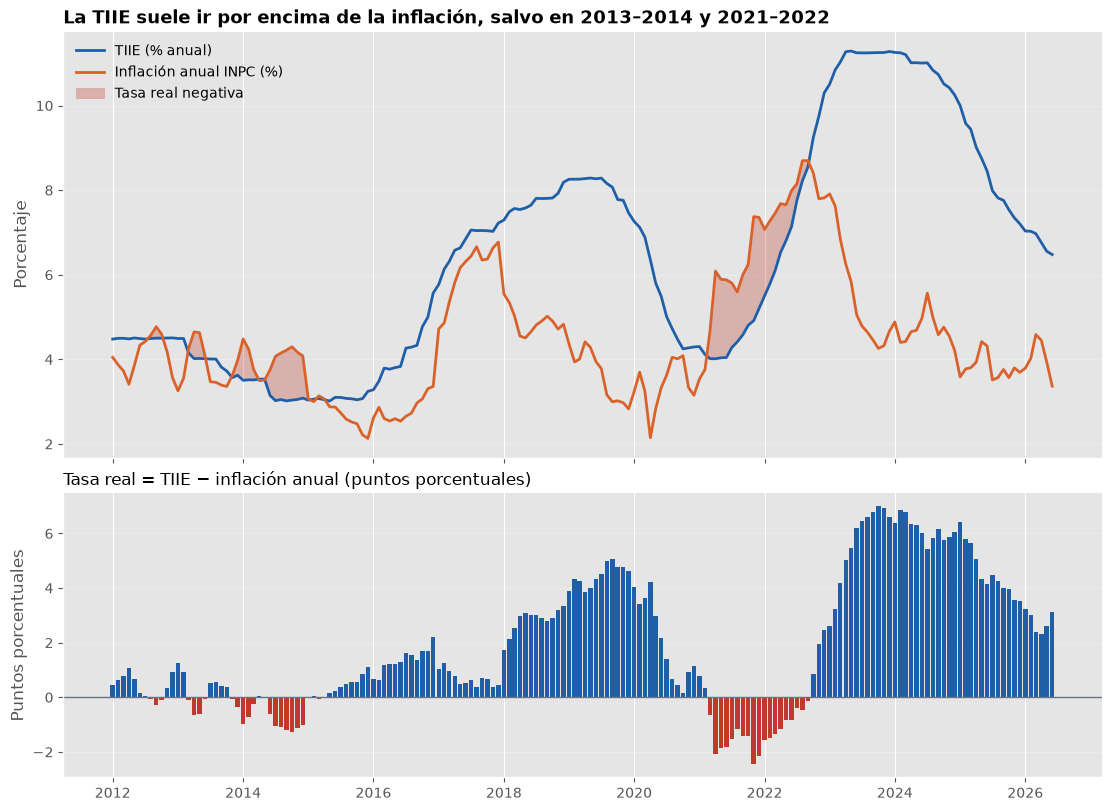

In [11]:
import os
os.makedirs("../docs/pregunta2", exist_ok=True)

AZUL, NARANJA, ROJO, GRIS = "#1F5FA8", "#D9622B", "#C0392B", "#6B7280"

pdf["FECHA"] = pd.to_datetime(pdf["CICLO"] + "-01")
neg_mask = (pdf["TASA_REAL"] < 0).to_numpy()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 8), sharex=True, constrained_layout=True,
                               gridspec_kw={"height_ratios": [3, 2]})

# Panel 1: TIIE vs inflación anual
ax1.plot(pdf["FECHA"], pdf["TIIE"], color=AZUL, lw=2, label="TIIE (% anual)")
ax1.plot(pdf["FECHA"], pdf["INFLACION_ANUAL"], color=NARANJA, lw=2, label="Inflación anual INPC (%)")
ax1.fill_between(pdf["FECHA"], pdf["TIIE"], pdf["INFLACION_ANUAL"], where=neg_mask,
                 interpolate=True, color=ROJO, alpha=0.30, label="Tasa real negativa")
ax1.set_title("La TIIE suele ir por encima de la inflación, salvo en 2013–2014 y 2021–2022", loc="left", fontsize=13, fontweight="bold")
ax1.set_ylabel("Porcentaje")
ax1.legend(frameon=False, loc="upper left")
ax1.grid(axis="y", alpha=0.25)

# Panel 2: tasa real
colores = [ROJO if v < 0 else AZUL for v in pdf["TASA_REAL"]]
ax2.bar(pdf["FECHA"], pdf["TASA_REAL"], width=25, color=colores)
ax2.axhline(0, color=GRIS, lw=1)
ax2.set_title("Tasa real = TIIE − inflación anual (puntos porcentuales)", loc="left", fontsize=12)
ax2.set_ylabel("Puntos porcentuales")
ax2.grid(axis="y", alpha=0.25)

for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)

fig.savefig("../docs/pregunta2/tiie_inpc_tasa_real.png", dpi=150)
plt.show()

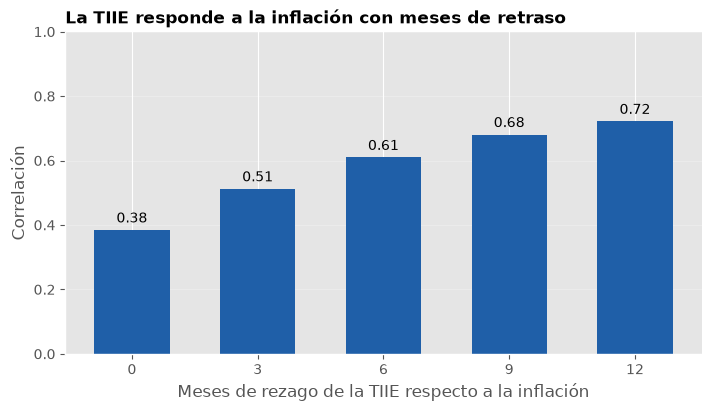

In [12]:
fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
barras = ax.bar(corr["REZAGO_MESES"].astype(str), corr["CORRELACION"], color=AZUL, width=0.6)
ax.bar_label(barras, fmt="%.2f", padding=3)
ax.set_ylim(0, 1)
ax.set_title("La TIIE responde a la inflación con meses de retraso", loc="left", fontsize=12, fontweight="bold")
ax.set_xlabel("Meses de rezago de la TIIE respecto a la inflación")
ax.set_ylabel("Correlación")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.25)

fig.savefig("../docs/pregunta2/tiie_inflacion_rezagos.png", dpi=150)
plt.show()

## 4.5 Limitaciones e interpretación prudente

- **Tasa real ex post.** Se compara la TIIE con la inflación que efectivamente ocurrió, no con la inflación que los agentes esperaban al fijar la tasa. Una tasa real "negativa" en el cálculo no implica que fuera negativa ex ante.
- **Correlación no es causalidad.** Que la TIIE siga a la inflación con rezago es consistente con una política monetaria reactiva, pero con una sola serie mensual no se puede aislar el efecto de la tasa sobre la inflación ni de otros factores (tipo de cambio, choques externos, expectativas).
- **Series con tendencia.** Las correlaciones entre series persistentes pueden inflarse por comovimientos largos; deben leerse como indicio descriptivo, no como estimación de un efecto.
- **Cobertura temporal.** Los datos van de 2011-01 a 2026-06. La inflación anual necesita 12 meses previos, por lo que el análisis de tasa real comienza en 2012-01 y los resultados dependen de los ciclos que caen en esa ventana.
- **Definición de las variables.** `TIIE` se toma como viene en el dataset (promedio mensual, según los decimales que presenta) y `VALOR_INPC` como nivel del índice; conviene confirmar con la documentación de la fuente el plazo de la TIIE y la base del INPC antes de publicar conclusiones.
- **Alcance.** Este bloque no incorpora deuda, ingresos ni gasto públicos; cualquier afirmación sobre su relación con la tasa real corresponde a otras preguntas del equipo.

## 8. Arquitectura aplicada (Etapa D)

Recorrido de los datos en el proyecto y lugar de este notebook:

```text
 Fuentes (CSV en data/raw)        Procesamiento             Almacenamiento            Consulta               Resultado
┌─────────────────────────┐     ┌────────────────┐        ┌──────────────────┐     ┌────────────────┐     ┌───────────────────────┐
│ deuda, finanzas, IGAE,  │ ──▶ │ PySpark (src/) │  ───▶  │ Parquet integrado│ ──▶ │ Spark SQL en   │ ──▶ │ Tablas e indicadores  │
│ TIIE, INPC              │     │ extract, clean,│        │ (data/processed) │     │ este notebook  │     │ + gráficas en         │
│                         │     │ validate, load │        │ mensual (CICLO)  │     │ (vistas tasa_  │     │ ..docs/pregunta2/     │
└─────────────────────────┘     └────────────────┘        └──────────────────┘     │ real, macro)   │     └───────────────────────┘
                                                                                    └────────────────┘
```

**Dónde se almacenan y cómo se reutilizan.** El pipeline deja el dataset integrado en formato Parquet, en disco local. El notebook lo lee con Spark, registra vistas temporales (`macro`, `tasa_real`) y ejecuta las consultas sin reescribir el dato base. Las vistas viven sólo mientras dura la sesión de Spark; lo que se conserva es el Parquet y las figuras guardadas en `..docs/pregunta2/`.

**Implementado hoy:** lectura de Parquet/CSV, consultas Spark SQL sobre vistas temporales y gráficas con matplotlib.
**Posible evolución (no implementada):** publicar la tabla de resultados en un Data Lake o Lakehouse con tablas versionadas, o mover la inflación anual y la tasa real al ETL si más preguntas las necesitan.

**Cómo se incorporarían nuevos datos o correcciones.** Se agregarían los meses nuevos a las fuentes de `data/raw` (o se corregiría el valor erróneo), se volvería a ejecutar el pipeline para regenerar el Parquet y se reejecutaría este notebook de arriba abajo. Las validaciones de la sección 2 detectan meses repetidos, huecos o nulos antes de calcular. No se implementa carga incremental porque el volumen (unos 186 registros) no la justifica.

### Cómo reproducir
1. Ejecutar el pipeline para generar el Parquet integrado (o dejar `macro_finanzas_consolidado.csv` en `data/raw/`).
2. Abrir este notebook desde la raíz del repositorio (o desde `notebooks/`) con PySpark, pandas y matplotlib instalados.
3. Ejecutar todas las celdas en orden. Las figuras se guardan en `..docs/pregunta2/`.

### 5. Pregunta Elba

In [13]:
### PONER CÓDIGO

### 6. Pregunta Mauricio

In [14]:
### PONER CÓDIGO

### 7.

In [15]:
### PONER CÓDIGO

### 8.

In [16]:
### PONER CÓDIGO